In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving model_ready_hourly_dataset.csv to model_ready_hourly_dataset.csv


In [ ]:
df = pd.read_csv('model_ready_hourly_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Shape:", df.shape)

df.head()

Shape: (1194600, 29)


,time,zone_id,volume,volume_11kw,duration,e_price,s_price,occupancy,date,hour,...,volume_11kw_outlier_flag,volume_11kw_capped,duration_outlier_flag,duration_capped,e_price_outlier_flag,e_price_capped,s_price_outlier_flag,s_price_capped,occupancy_outlier_flag,occupancy_capped
0,2022-09-01 00:00:00,1000,330.458333,330.458333,60.833333,0.873429,0.739429,74.0,2022-09-01,0,...,0,330.458333,0,60.833333,0,0.873429,0,0.739429,0,74.0
1,2022-09-01 00:00:00,1009,363.708333,363.708333,55.250000,0.913818,0.748909,66.0,2022-09-01,0,...,0,363.708333,0,55.250000,0,0.913818,0,0.748909,0,66.0
2,2022-09-01 00:00:00,1011,516.833333,516.833333,79.666667,0.880820,0.754302,108.0,2022-09-01,0,...,0,516.833333,0,79.666667,0,0.880820,0,0.754302,0,108.0
3,2022-09-01 00:00:00,1015,147.583333,147.583333,21.083333,1.100000,0.760000,19.0,2022-09-01,0,...,0,147.583333,0,21.083333,0,1.100000,0,0.760000,0,19.0
4,2022-09-01 00:00:00,102,56.291667,56.291667,8.833333,0.924000,0.856000,17.0,2022-09-01,0,...,0,56.291667,0,8.833333,0,0.924000,0,0.856000,0,17.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1194600 entries, 0 to 1194599
Data columns (total 29 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   time                      1194600 non-null  object 
 1   zone_id                   1194600 non-null  int64  
 2   volume                    1194600 non-null  float64
 3   volume_11kw               1194600 non-null  float64
 4   duration                  1194600 non-null  float64
 5   e_price                   1194600 non-null  float64
 6   s_price                   1194600 non-null  float64
 7   occupancy                 1194600 non-null  float64
 8   date                      1194600 non-null  object 
 9   hour                      1194600 non-null  int64  
 10  day                       1194600 non-null  int64  
 11  day_of_week               1194600 non-null  int64  
 12  day_name                  1194600 non-null  object 
 13  month                     1

In [ ]:
df.isnull().sum()

,0
time,0
zone_id,0
volume,0
volume_11kw,0
duration,0
e_price,0
s_price,0
occupancy,0
date,0
hour,0


In [ ]:
df.describe()

,zone_id,volume,volume_11kw,duration,e_price,s_price,occupancy,hour,day,day_of_week,...,volume_11kw_outlier_flag,volume_11kw_capped,duration_outlier_flag,duration_capped,e_price_outlier_flag,e_price_capped,s_price_outlier_flag,s_price_capped,occupancy_outlier_flag,occupancy_capped
count,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,...,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06,1.194600e+06
mean,7.337709e+02,2.614648e+02,1.028661e+02,1.310555e+01,9.511962e-01,7.240598e-01,1.786646e+01,1.150000e+01,1.560221e+01,3.005525e+00,...,1.025197e-02,1.027553e+02,9.952285e-03,1.309409e+01,5.160723e-03,9.512349e-01,1.479993e-03,7.240395e-01,1.589235e-02,1.782970e+01
std,3.095235e+02,8.597679e+02,1.843761e+02,1.721985e+01,1.948829e-01,1.289864e-01,2.101456e+01,6.922189e+00,8.735326e+00,2.004133e+00,...,1.007317e-01,1.842203e+02,9.926352e-02,1.720321e+01,7.165260e-02,1.949100e-01,3.844222e-02,1.289742e-01,1.250592e-01,2.094651e+01
min,1.020000e+02,0.000000e+00,0.000000e+00,0.000000e+00,2.380600e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.380600e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.270000e+02,1.866667e+01,1.750000e+01,2.666667e+00,8.166667e-01,7.100000e-01,5.000000e+00,5.750000e+00,8.000000e+00,1.000000e+00,...,0.000000e+00,1.750000e+01,0.000000e+00,2.583333e+00,0.000000e+00,8.166667e-01,0.000000e+00,7.100000e-01,0.000000e+00,5.000000e+00
50%,7.370000e+02,5.366667e+01,4.900000e+01,7.000000e+00,9.600000e-01,7.600000e-01,1.100000e+01,1.150000e+01,1.600000e+01,3.000000e+00,...,0.000000e+00,4.900000e+01,0.000000e+00,7.000000e+00,0.000000e+00,9.600000e-01,0.000000e+00,7.600000e-01,0.000000e+00,1.050000e+01
75%,1.009000e+03,1.525833e+02,1.198750e+02,1.625000e+01,1.060000e+00,7.600000e-01,2.300000e+01,1.725000e+01,2.300000e+01,5.000000e+00,...,0.000000e+00,1.195833e+02,0.000000e+00,1.625000e+01,0.000000e+00,1.060000e+00,0.000000e+00,7.600000e-01,0.000000e+00,2.200000e+01
max,1.173000e+03,1.673250e+04,5.073000e+03,2.075833e+02,1.800000e+00,1.450000e+00,3.730000e+02,2.300000e+01,3.100000e+01,6.000000e+00,...,1.000000e+00,5.073000e+03,1.000000e+00,2.075833e+02,1.000000e+00,1.800000e+00,1.000000e+00,1.450000e+00,1.000000e+00,2.755000e+02


In [ ]:
print("All dataset columns:\n")

for col in df.columns:
    print(col)

All dataset columns:

time
zone_id
volume
volume_11kw
duration
e_price
s_price
occupancy
date
hour
day
day_of_week
day_name
month
month_name
weekend
week_of_year
volume_outlier_flag
volume_capped
volume_11kw_outlier_flag
volume_11kw_capped
duration_outlier_flag
duration_capped
e_price_outlier_flag
e_price_capped
s_price_outlier_flag
s_price_capped
occupancy_outlier_flag
occupancy_capped


In [ ]:
df.head(5).T

,0,1,2,3,4
time,2022-09-01 00:00:00,2022-09-01 00:00:00,2022-09-01 00:00:00,2022-09-01 00:00:00,2022-09-01 00:00:00
zone_id,1000,1009,1011,1015,102
volume,330.458333,363.708333,516.833333,147.583333,56.291667
volume_11kw,330.458333,363.708333,516.833333,147.583333,56.291667
duration,60.833333,55.25,79.666667,21.083333,8.833333
e_price,0.873429,0.913818,0.88082,1.1,0.924
s_price,0.739429,0.748909,0.754302,0.76,0.856
occupancy,74.0,66.0,108.0,19.0,17.0
date,2022-09-01,2022-09-01,2022-09-01,2022-09-01,2022-09-01
hour,0,0,0,0,0


In [ ]:
df['time'] = pd.to_datetime(df['time'])

df = df.sort_values(['zone_id', 'time'])

df = df.reset_index(drop=True)

print("Datetime conversion successful!")
print(df['time'].dtype)

Datetime conversion successful!
datetime64[ns]


In [ ]:
print("Starting date:", df['time'].min())
print("Ending date:", df['time'].max())

print("Unique timestamps:", df['time'].nunique())

print("Unique zones:", df['zone_id'].nunique())

Starting date: 2022-09-01 00:00:00
Ending date: 2023-02-28 23:00:00
Unique timestamps: 4344
Unique zones: 275


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate zone-time combinations:",
      df.duplicated(subset=['zone_id', 'time']).sum())

Total duplicate rows: 0
Duplicate zone-time combinations: 0


In [ ]:
target_columns = [
    col for col in df.columns
    if 'volume' in col.lower()
    or 'occupancy' in col.lower()
]

print("Potential prediction targets:")

for col in target_columns:
    print(col)

Potential prediction targets:
volume
volume_11kw
occupancy
volume_outlier_flag
volume_capped
volume_11kw_outlier_flag
volume_11kw_capped
occupancy_outlier_flag
occupancy_capped


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hourly_system_summary.csv to hourly_system_summary.csv


In [ ]:
system_df = pd.read_csv('hourly_system_summary.csv')

print("Dataset loaded successfully!")
print("Shape:", system_df.shape)

system_df.head()

Dataset loaded successfully!
Shape: (4344, 7)


,time,total_volume,total_volume_11kw,total_occupancy,mean_duration,mean_e_price,mean_s_price
0,2022-09-01 00:00:00,121029.166667,38861.833333,5753.0,17.564545,0.899585,0.763734
1,2022-09-01 01:00:00,123237.275000,41437.400000,5938.5,18.073636,0.899519,0.763217
2,2022-09-01 02:00:00,109904.191667,39899.775000,6374.5,17.767879,0.899537,0.763946
3,2022-09-01 03:00:00,102283.433333,39852.975000,6310.0,17.814242,0.899610,0.763946
4,2022-09-01 04:00:00,97138.066667,37552.566667,5805.5,17.361818,0.899585,0.763253


In [ ]:
system_df['time'] = pd.to_datetime(system_df['time'])

system_df = system_df.sort_values('time').reset_index(drop=True)

system_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4344 entries, 0 to 4343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   time               4344 non-null   datetime64[ns]
 1   total_volume       4344 non-null   float64       
 2   total_volume_11kw  4344 non-null   float64       
 3   total_occupancy    4344 non-null   float64       
 4   mean_duration      4344 non-null   float64       
 5   mean_e_price       4344 non-null   float64       
 6   mean_s_price       4344 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 237.7 KB


In [ ]:
system_df.head()

,time,total_volume,total_volume_11kw,total_occupancy,mean_duration,mean_e_price,mean_s_price
0,2022-09-01 00:00:00,121029.166667,38861.833333,5753.0,17.564545,0.899585,0.763734
1,2022-09-01 01:00:00,123237.275000,41437.400000,5938.5,18.073636,0.899519,0.763217
2,2022-09-01 02:00:00,109904.191667,39899.775000,6374.5,17.767879,0.899537,0.763946
3,2022-09-01 03:00:00,102283.433333,39852.975000,6310.0,17.814242,0.899610,0.763946
4,2022-09-01 04:00:00,97138.066667,37552.566667,5805.5,17.361818,0.899585,0.763253


In [ ]:
system_df['hour'] = system_df['time'].dt.hour

system_df['day'] = system_df['time'].dt.day

system_df['day_of_week'] = system_df['time'].dt.dayofweek

system_df['month'] = system_df['time'].dt.month

system_df['weekend'] = (
    system_df['day_of_week'] >= 5
).astype(int)

print("Time-based features created!")

Time-based features created!


In [ ]:
system_df['is_peak_hour'] = (
    ((system_df['hour'] >= 7) & (system_df['hour'] <= 10)) |
    ((system_df['hour'] >= 17) & (system_df['hour'] <= 21))
).astype(int)

system_df.head()

,time,total_volume,total_volume_11kw,total_occupancy,mean_duration,mean_e_price,mean_s_price,hour,day,day_of_week,month,weekend,is_peak_hour
0,2022-09-01 00:00:00,121029.166667,38861.833333,5753.0,17.564545,0.899585,0.763734,0,1,3,9,0,0
1,2022-09-01 01:00:00,123237.275000,41437.400000,5938.5,18.073636,0.899519,0.763217,1,1,3,9,0,0
2,2022-09-01 02:00:00,109904.191667,39899.775000,6374.5,17.767879,0.899537,0.763946,2,1,3,9,0,0
3,2022-09-01 03:00:00,102283.433333,39852.975000,6310.0,17.814242,0.899610,0.763946,3,1,3,9,0,0
4,2022-09-01 04:00:00,97138.066667,37552.566667,5805.5,17.361818,0.899585,0.763253,4,1,3,9,0,0


In [ ]:
target_columns = [
    'total_volume',
    'total_volume_11kw'
]

for col in target_columns:
    system_df[f'{col}_lag_1'] = system_df[col].shift(1)
    system_df[f'{col}_lag_24'] = system_df[col].shift(24)
    system_df[f'{col}_lag_168'] = system_df[col].shift(168)

print("Lag features created!")

Lag features created!


In [ ]:
for col in target_columns:
    system_df[f'{col}_rolling_24'] = (
        system_df[col].shift(1).rolling(window=24).mean()
    )

print("Rolling average features created!")

Rolling average features created!


In [ ]:
print("Shape before removing missing values:", system_df.shape)

system_df = system_df.dropna().reset_index(drop=True)

print("Shape after removing missing values:", system_df.shape)

Shape before removing missing values: (4344, 21)
Shape after removing missing values: (4176, 21)


In [ ]:
print("Final dataset shape:", system_df.shape)

print("\nAll columns:")
print(system_df.columns.tolist())

system_df.head()

Final dataset shape: (4176, 21)

All columns:
['time', 'total_volume', 'total_volume_11kw', 'total_occupancy', 'mean_duration', 'mean_e_price', 'mean_s_price', 'hour', 'day', 'day_of_week', 'month', 'weekend', 'is_peak_hour', 'total_volume_lag_1', 'total_volume_lag_24', 'total_volume_lag_168', 'total_volume_11kw_lag_1', 'total_volume_11kw_lag_24', 'total_volume_11kw_lag_168', 'total_volume_rolling_24', 'total_volume_11kw_rolling_24']


,time,total_volume,total_volume_11kw,total_occupancy,mean_duration,mean_e_price,mean_s_price,hour,day,day_of_week,...,weekend,is_peak_hour,total_volume_lag_1,total_volume_lag_24,total_volume_lag_168,total_volume_11kw_lag_1,total_volume_11kw_lag_24,total_volume_11kw_lag_168,total_volume_rolling_24,total_volume_11kw_rolling_24
0,2022-09-08 00:00:00,131769.050000,39278.216667,5577.0,17.002121,0.901073,0.759883,0,8,3,...,0,0,76722.483333,131663.258333,121029.166667,31730.233333,38596.508333,38861.833333,77673.142477,28686.482176
1,2022-09-08 01:00:00,132243.416667,39531.250000,5821.0,17.111212,0.899057,0.762647,1,8,3,...,0,0,131769.050000,125737.425000,123237.275000,39278.216667,38849.258333,41437.400000,77677.550463,28714.886690
2,2022-09-08 02:00:00,110396.316667,38301.275000,5696.0,16.658788,0.899057,0.762647,2,8,3,...,0,0,132243.416667,102908.716667,109904.191667,39531.250000,36957.550000,39899.775000,77948.633449,28743.303009
3,2022-09-08 03:00:00,100571.858333,37053.525000,5628.0,16.421212,0.899057,0.762647,3,8,3,...,0,0,110396.316667,94827.550000,102283.433333,38301.275000,35934.466667,39852.975000,78260.616782,28799.291551
4,2022-09-08 04:00:00,95908.550000,35578.300000,5799.0,16.240303,0.899057,0.762647,4,8,3,...,0,0,100571.858333,95964.008333,97138.066667,37053.525000,35622.341667,37552.566667,78499.962963,28845.918981


In [ ]:
system_df.to_csv('ML_Feature_Engineered_Dataset.csv', index=False)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

In [ ]:
features = [
    'hour',
    'day_of_week',
    'month',
    'weekend',
    'is_peak_hour'
]

In [ ]:
for col in ['total_volume', 'total_volume_11kw']:
    features.extend([
        f'{col}_lag_1',
        f'{col}_lag_24',
        f'{col}_lag_168',
        f'{col}_rolling_24'
    ])

print("Selected features:")
print(features)

Selected features:
['hour', 'day_of_week', 'month', 'weekend', 'is_peak_hour', 'total_volume_lag_1', 'total_volume_lag_24', 'total_volume_lag_168', 'total_volume_rolling_24', 'total_volume_11kw_lag_1', 'total_volume_11kw_lag_24', 'total_volume_11kw_lag_168', 'total_volume_11kw_rolling_24']


In [ ]:
split_index = int(len(system_df) * 0.80)

train_df = system_df.iloc[:split_index].copy()
test_df = system_df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("Training period:")
print(train_df['time'].min(), "to", train_df['time'].max())

print("\nTesting period:")
print(test_df['time'].min(), "to", test_df['time'].max())

Training records: 3340
Testing records: 836
Training period:
2022-09-08 00:00:00 to 2023-01-25 03:00:00

Testing period:
2023-01-25 04:00:00 to 2023-02-28 23:00:00


In [ ]:
target = 'total_volume'

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3340, 13)
X_test: (836, 13)
y_train: (3340,)
y_test: (836,)


In [ ]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [ ]:
mae = mean_absolute_error(y_test, lr_predictions)

rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MAE: 5502.816852723362
RMSE: 7141.3659718734125
R2 Score: 0.9069949752559093


In [ ]:
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
mae = mean_absolute_error(y_test, dt_predictions)

rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))

r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results")
print("----------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Decision Tree Results
----------------------
MAE: 5355.161706425155
RMSE: 7622.376960481576
R2 Score: 0.894044213757951


In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
mae = mean_absolute_error(y_test, rf_predictions)

rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Random Forest Results
---------------------
MAE: 3884.2765987504445
RMSE: 5412.067010206061
R2 Score: 0.9465841475673081


In [ ]:
results = []

models_predictions = {
    'Linear Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions
}

for model_name, predictions in models_predictions.items():

    results.append({
        'Model': model_name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,5502.816853,7141.365972,0.906995
1,Decision Tree,5355.161706,7622.376960,0.894044
2,Random Forest,3884.276599,5412.067010,0.946584


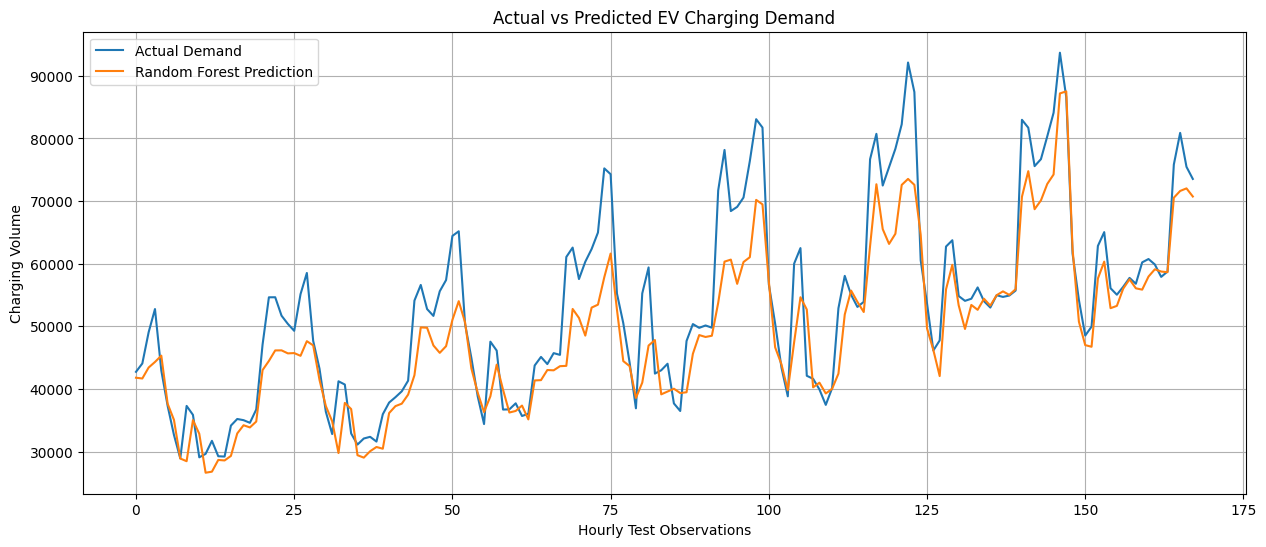

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.values[:168],
    label='Actual Demand'
)

plt.plot(
    rf_predictions[:168],
    label='Random Forest Prediction'
)

plt.title('Actual vs Predicted EV Charging Demand')
plt.xlabel('Hourly Test Observations')
plt.ylabel('Charging Volume')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
target_2 = 'total_volume_11kw'

X_train_2 = train_df[features]
X_test_2 = test_df[features]

y_train_2 = train_df[target_2]
y_test_2 = test_df[target_2]

print("Training data:", X_train_2.shape)
print("Testing data:", X_test_2.shape)

Training data: (3340, 13)
Testing data: (836, 13)


In [ ]:
lr_model_2 = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

lr_model_2.fit(X_train_2, y_train_2)

lr_predictions_2 = lr_model_2.predict(X_test_2)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [ ]:
print("Linear Regression Results")

print("MAE:", mean_absolute_error(y_test_2, lr_predictions_2))

print("RMSE:", np.sqrt(mean_squared_error(y_test_2, lr_predictions_2)))

print("R2 Score:", r2_score(y_test_2, lr_predictions_2))

Linear Regression Results
MAE: 1250.9084978455924
RMSE: 1599.676477683107
R2 Score: 0.9326053982887375


In [ ]:
dt_model_2 = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model_2.fit(X_train_2, y_train_2)

dt_predictions_2 = dt_model_2.predict(X_test_2)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
print("Decision Tree Results")

print("MAE:", mean_absolute_error(y_test_2, dt_predictions_2))

print("RMSE:", np.sqrt(mean_squared_error(y_test_2, dt_predictions_2)))

print("R2 Score:", r2_score(y_test_2, dt_predictions_2))

Decision Tree Results
MAE: 1360.9692080058119
RMSE: 1797.0763226016218
R2 Score: 0.9149461772462942


In [ ]:
rf_model_2 = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model_2.fit(X_train_2, y_train_2)

rf_predictions_2 = rf_model_2.predict(X_test_2)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
print("Random Forest Results")

print("MAE:", mean_absolute_error(y_test_2, rf_predictions_2))

print("RMSE:", np.sqrt(mean_squared_error(y_test_2, rf_predictions_2)))

print("R2 Score:", r2_score(y_test_2, rf_predictions_2))

Random Forest Results
MAE: 961.688086911463
RMSE: 1294.6762450098693
R2 Score: 0.955854834172005


In [ ]:
results_2 = []

models_2 = {
    'Linear Regression': lr_predictions_2,
    'Decision Tree': dt_predictions_2,
    'Random Forest': rf_predictions_2
}

for name, predictions in models_2.items():

    results_2.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_2, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test_2, predictions)),
        'R2 Score': r2_score(y_test_2, predictions)
    })

results_df_2 = pd.DataFrame(results_2)

results_df_2.sort_values('RMSE')

,Model,MAE,RMSE,R2 Score
2,Random Forest,961.688087,1294.676245,0.955855
0,Linear Regression,1250.908498,1599.676478,0.932605
1,Decision Tree,1360.969208,1797.076323,0.914946


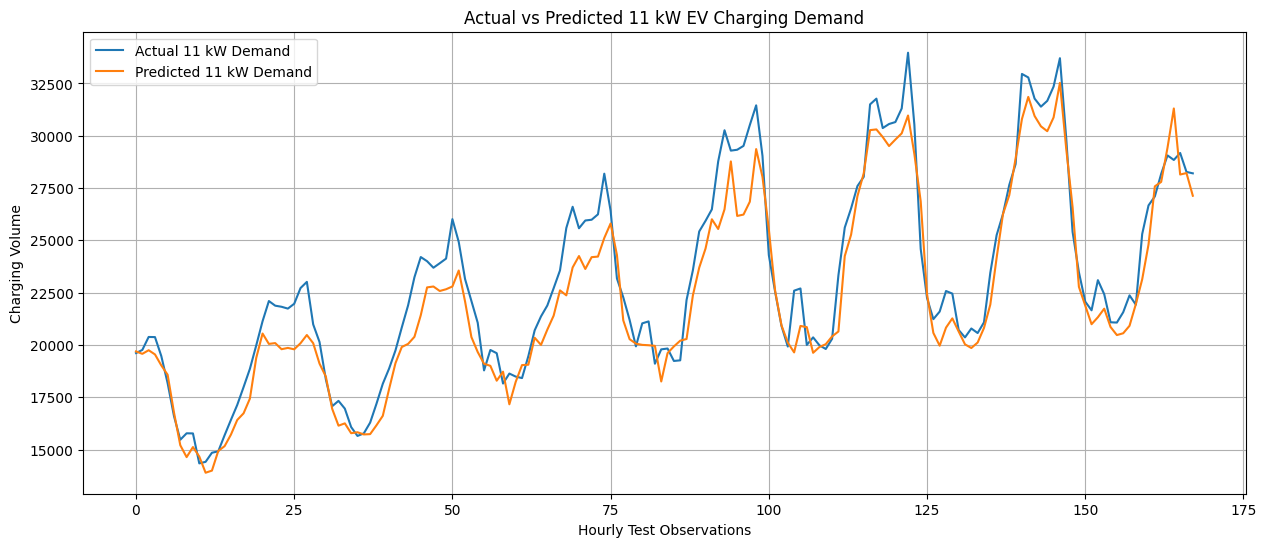

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_2.values[:168],
    label='Actual 11 kW Demand'
)

plt.plot(
    rf_predictions_2[:168],
    label='Predicted 11 kW Demand'
)

plt.title('Actual vs Predicted 11 kW EV Charging Demand')
plt.xlabel('Hourly Test Observations')
plt.ylabel('Charging Volume')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
predictions_df = pd.DataFrame({
    'time': test_df['time'].values,
    'actual_total_volume': y_test.values,
    'predicted_total_volume': rf_predictions,
    'actual_volume_11kw': y_test_2.values,
    'predicted_volume_11kw': rf_predictions_2
})

predictions_df.to_csv('EV_Demand_Predictions.csv', index=False)

print("Predictions exported successfully!")

Predictions exported successfully!


In [ ]:
comparison_1 = results_df.copy()
comparison_1['Target'] = 'Total Charging Volume'

comparison_2 = results_df_2.copy()
comparison_2['Target'] = '11 kW Charging Volume'

final_comparison = pd.concat(
    [comparison_1, comparison_2],
    ignore_index=True
)

final_comparison.to_csv(
    'ML_Model_Comparison.csv',
    index=False
)

final_comparison

,Model,MAE,RMSE,R2 Score,Target
0,Linear Regression,5502.816853,7141.365972,0.906995,Total Charging Volume
1,Decision Tree,5355.161706,7622.376960,0.894044,Total Charging Volume
2,Random Forest,3884.276599,5412.067010,0.946584,Total Charging Volume
3,Linear Regression,1250.908498,1599.676478,0.932605,11 kW Charging Volume
4,Decision Tree,1360.969208,1797.076323,0.914946,11 kW Charging Volume
5,Random Forest,961.688087,1294.676245,0.955855,11 kW Charging Volume


In [ ]:
from google.colab import files

files.download('EV_Demand_Predictions.csv')
files.download('ML_Model_Comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

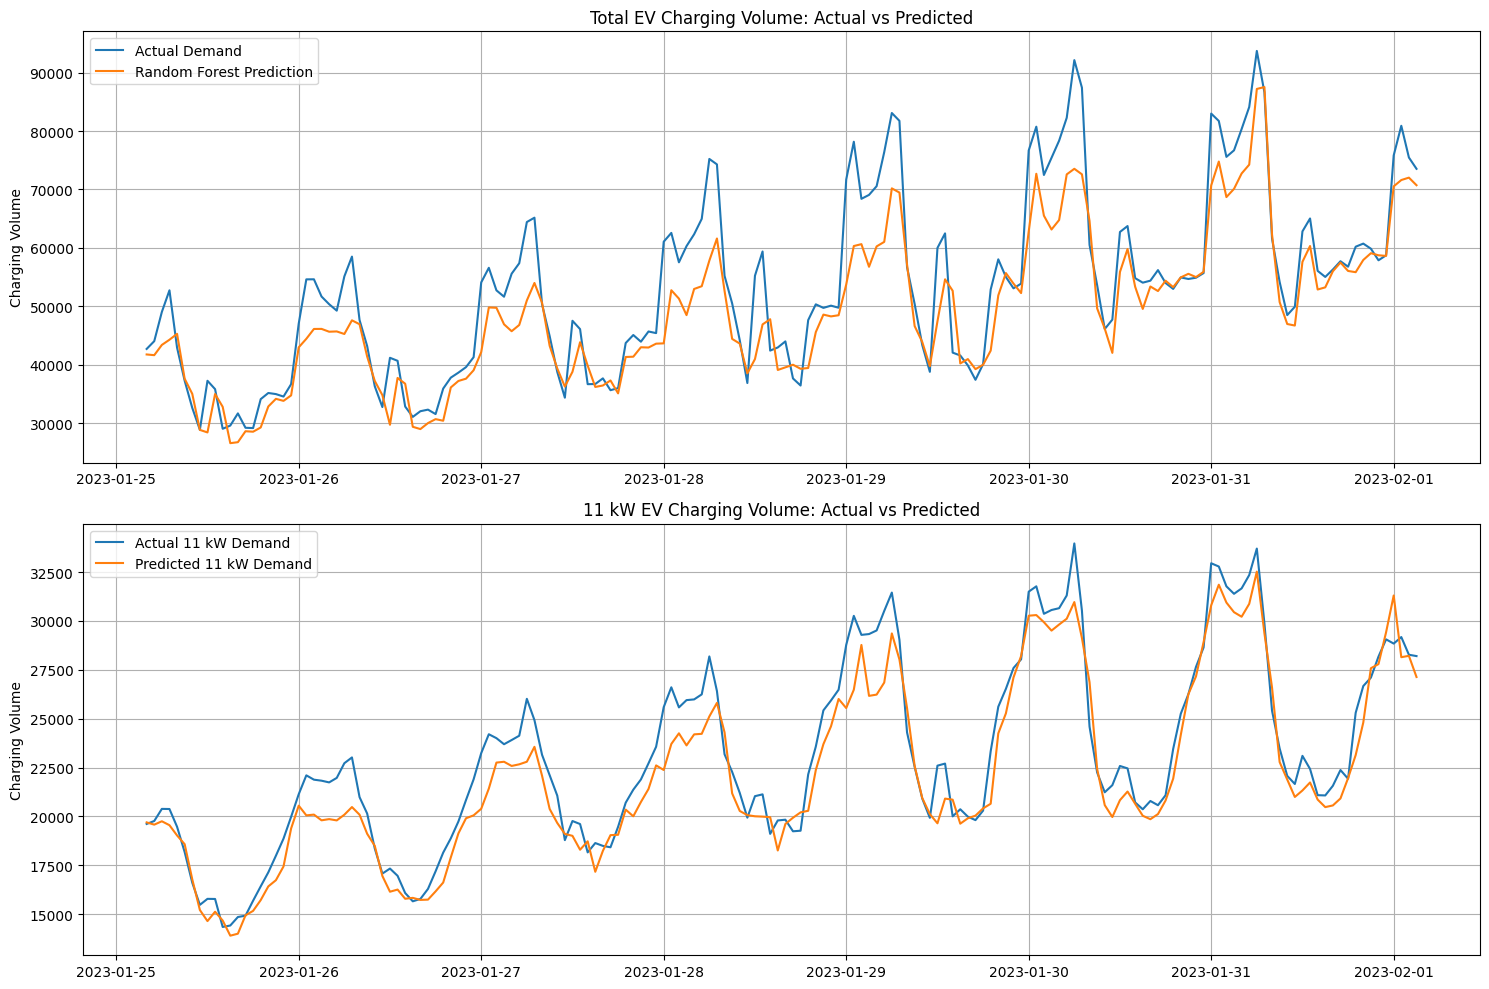

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(
    test_df['time'].values[:168],
    y_test.values[:168],
    label='Actual Demand'
)

axes[0].plot(
    test_df['time'].values[:168],
    rf_predictions[:168],
    label='Random Forest Prediction'
)

axes[0].set_title('Total EV Charging Volume: Actual vs Predicted')
axes[0].set_ylabel('Charging Volume')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    test_df['time'].values[:168],
    y_test_2.values[:168],
    label='Actual 11 kW Demand'
)

axes[1].plot(
    test_df['time'].values[:168],
    rf_predictions_2[:168],
    label='Predicted 11 kW Demand'
)

axes[1].set_title('11 kW EV Charging Volume: Actual vs Predicted')
axes[1].set_ylabel('Charging Volume')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
baseline_1 = test_df['total_volume_lag_24']

print("Baseline - Total Charging Volume")
print("MAE:", mean_absolute_error(y_test, baseline_1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, baseline_1)))
print("R2:", r2_score(y_test, baseline_1))

Baseline - Total Charging Volume
MAE: 4263.981998438331
RMSE: 5744.195339817732
R2: 0.9398269211259276


In [ ]:
baseline_2 = test_df['total_volume_11kw_lag_24']

print("Baseline - 11 kW Charging Volume")
print("MAE:", mean_absolute_error(y_test_2, baseline_2))
print("RMSE:", np.sqrt(mean_squared_error(y_test_2, baseline_2)))
print("R2:", r2_score(y_test_2, baseline_2))

Baseline - 11 kW Charging Volume
MAE: 1436.1039915452372
RMSE: 2008.9593891755853
R2: 0.8937073808207201


In [ ]:
baseline_results = pd.DataFrame([
    {
        'Model': 'Baseline (Lag 24)',
        'MAE': mean_absolute_error(y_test, baseline_1),
        'RMSE': np.sqrt(mean_squared_error(y_test, baseline_1)),
        'R2 Score': r2_score(y_test, baseline_1),
        'Target': 'Total Charging Volume'
    },
    {
        'Model': 'Baseline (Lag 24)',
        'MAE': mean_absolute_error(y_test_2, baseline_2),
        'RMSE': np.sqrt(mean_squared_error(y_test_2, baseline_2)),
        'R2 Score': r2_score(y_test_2, baseline_2),
        'Target': '11 kW Charging Volume'
    }
])

final_comparison = pd.concat(
    [final_comparison, baseline_results],
    ignore_index=True
)

final_comparison.to_csv(
    'EV_ML_Models/Final_Model_Comparison.csv',
    index=False
)

final_comparison

,Model,MAE,RMSE,R2 Score,Target
0,Linear Regression,5502.816853,7141.365972,0.906995,Total Charging Volume
1,Decision Tree,5355.161706,7622.376960,0.894044,Total Charging Volume
2,Random Forest,3884.276599,5412.067010,0.946584,Total Charging Volume
3,Linear Regression,1250.908498,1599.676478,0.932605,11 kW Charging Volume
4,Decision Tree,1360.969208,1797.076323,0.914946,11 kW Charging Volume
5,Random Forest,961.688087,1294.676245,0.955855,11 kW Charging Volume
6,Baseline (Lag 24),4263.981998,5744.195340,0.939827,Total Charging Volume
7,Baseline (Lag 24),1436.103992,2008.959389,0.893707,11 kW Charging Volume


In [ ]:
import joblib
import os

os.makedirs('EV_ML_Models', exist_ok=True)

joblib.dump(
    rf_model,
    'EV_ML_Models/total_volume_random_forest.pkl'
)

joblib.dump(
    rf_model_2,
    'EV_ML_Models/volume_11kw_random_forest.pkl'
)

print("Both Random Forest models saved successfully!")

Both Random Forest models saved successfully!


In [ ]:
final_comparison.to_csv(
    'EV_ML_Models/Final_Model_Comparison.csv',
    index=False
)

print("Model comparison exported!")

Model comparison exported!


In [ ]:
predictions_df.to_csv(
    'EV_ML_Models/Final_EV_Demand_Predictions.csv',
    index=False
)

print("Final predictions exported!")

Final predictions exported!


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    'EV_ML_Models',
    'zip',
    'EV_ML_Models'
)

files.download('EV_ML_Models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json

with open('EV_ML_Models/model_features.json', 'w') as f:
    json.dump(features, f, indent=4)